# 03 NetworkX 的基础操作及画图

> **模块**：图论与网络 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、matplotlib、networkx

## 1. 问题背景

图论的研究是运筹学的一个经典而重要的分支，是很多领域研究的基础工具，在交通运输、经济管理和工业工程等都有广泛的应用。对于许多优化问题，可以利用图与网络的固有特性所形成的特定方法来解决，比用数学规划等其他模型求解往往要简单且有效得多。

“工欲善其事，必先利其器”，一个优秀的工具能帮助我们更专注于网络本身，而非费心去选择某种语言去实现算法、绘制图形。NetworkX作为Python的一个开源包，便于用户对复杂网络进行创建、操作和学习。利用networkx可以以标准化和非标准化的数据格式存储网络、生成多种随机网络和经典网络、分析网络结构、建立网络模型、设计新的网络算法、进行网络绘制等。


## 2. 学习目标

- 掌握 NetworkX 的基础操作
- 掌握使用 NetworkX 创建无向图和有向图


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 图的基本概念

#### 4.1.1 图

图：由一些点和这些点之间的连线组成。

定义一个图为 $ G = (V,E) $ 由一些点及点之间的连线（称为边）构成。
- $ V $：顶点的非空有限集合，称为顶点集
- $ E $：边的集合，称为边集，边一般用 $(v_i,v_j)$ 表示，其中 $v_i,v_j$ 属于顶点集 $V$

在图的概念中，点的空间位置，边的长度都无关紧要，重要的是其中有几个点以及那些点之间有边相连。

> *原稿配图未随 notebook 保存，此处暂缺。*

#### 4.1.2 无向图和有向图

NetworkX 提供了四种类型的图，如下：
- `networkx.Graph()` ：创建无向图
- `networkx.DiGraph()` ：创建有向图
- `networkx.MultiGraph()` ：创建多重无向图
- `networkx.MultiDigraph()` ：创建多重有向图

如果图的边是没有方向的，则称此图为无向图，无向图的边称为无向边（简称边），如下图右侧图形，连接两顶点 $X_1$ 和 $X_2$ 的无向边记为 $(X_1,X_2)$ 或 $(X_2,X_1)$。

如果图的边是有方向（带箭头）的，则称此图为有向图，有向图的边称为弧（或有向边），如下图左侧图形，连接两顶点 $X_1$ 和 $X_2$ 的弧记为 $\langle X_1,X_2 \rangle$，其中 $X_1$ 称为起点，$X_2$ 称为终点。显然此时弧 $\langle X_1,X_2 \rangle$ 与弧 $\langle X_2,X_1 \rangle$ 是不同的两条有向边。

有向图一般记为 $D = (V,A)$，其中 $V$ 为顶点集，$A$ 为弧集。

> *原稿配图未随 notebook 保存，此处暂缺。*

接下来，以无向图为例，基于networkx实现。

##### 4.1.2.1 创建无向图


In [3]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

G = nx.Graph()  # 创建无向图
G

##### 4.1.2.2 添加节点

- `add_node()`：添加一个顶点
- `add_edge()`：添加一条边
- `add_nodes_from(List)`：从列表中添加多个顶点
- `add_edges_from(List)`：从列表中添加多条边

In [4]:

G.add_node(1)  # 向图中增加一个顶点
print("输出全部节点：{}".format(G.nodes()))
 
List = [2,3,4] # 向图中增加三个顶点
G.add_nodes_from(List)
print("输出全部节点：{}".format(G.nodes()))

输出全部节点：[1]
输出全部节点：[1, 2, 3, 4]


In [5]:
G.add_edge(2, 3)
print("输出全部边：{}".format(G.edges()))
print("输出全部边的数量：{}".format(G.number_of_edges()))
List = [(1,2),(1,3)]
G.add_edges_from(List)
print("输出全部边：{}".format(G.edges()))
print("输出全部边的数量：{}".format(G.number_of_edges()))

输出全部边：[(2, 3)]
输出全部边的数量：1
输出全部边：[(1, 2), (1, 3), (2, 3)]
输出全部边的数量：3


##### 4.1.2.3 删除节点

- `remove_node()`：删除顶点
- `remove_edge()`：删除边

In [6]:
G.remove_node(2) # 删除顶点2
# G.remove_nodes_from([1,2])

G.add_nodes_from([4,5])  # 增加顶点4,5
print("输出全部节点：{}".format(G.nodes()))


G.add_edges_from([(1,4),(3,4),(3,5)]) # 增加边(1,4),(3,4),(3,5)
G.remove_edge(3, 4) # 删除边(3, 4)

print("输出全部边：{}".format(G.edges()))
print("输出全部边的数量：{}".format(G.number_of_edges()))

输出全部节点：[1, 3, 4, 5]
输出全部边：[(1, 3), (1, 4), (3, 5)]
输出全部边的数量：3


顶点一旦删除，对应的边也随之删除。

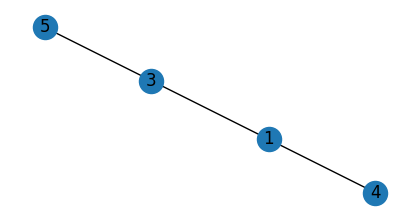

In [7]:
# nx.draw()绘制图形
# with_labels节点是否带标签

plt.figure(figsize=(4, 2)) 
nx.draw(G, with_labels=True)

### 4.2 由邻接矩阵创建图

邻接矩阵是一种图的存储方法，就是利用二维矩阵表示图中各顶点之间的关系，对于有n个顶点的图来说，用n阶方阵来表示该图，其中矩阵元素$A_{ij}$表示从顶点$v_i$到$v_j$之间的边,$A_{ij}$的大小表示边的权值。

**注意：当两个顶点之间不存在边时，根据实际问题的含义或算法需要，对应的权重可以取为0或$∞$。**

> *原稿配图未随 notebook 保存，此处暂缺。*

无向图的邻接矩阵一定是对称的。

> *原稿配图未随 notebook 保存，此处暂缺。*

所以如下图所示为一无向图和其邻接矩阵。

> *原稿配图未随 notebook 保存，此处暂缺。*

#### 4.2.1 无向图

接下来根据邻接矩阵创建无向图


输出全部节点：[0, 1, 2, 3, 4]
输出全部边：[(0, 1), (0, 2), (0, 3), (0, 4), (1, 2), (1, 3), (2, 3), (2, 4), (3, 4)]
输出全部边的数量：9


<Figure size 400x200 with 0 Axes>

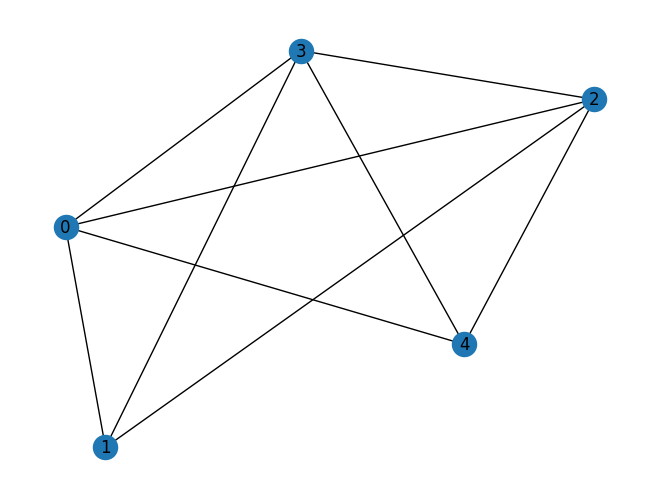

<Figure size 400x200 with 0 Axes>

In [8]:
#清空图
G.clear() 
# 创建邻接矩阵
A = np.array([[0,9,2,4,7],
              [9,0,3,4,0],
              [2,3,0,8,4],
              [4,4,8,0,6],
              [7,0,4,6,0]])
# 创建无向图
G = nx.Graph(A)
print("输出全部节点：{}".format(G.nodes()))
print("输出全部边：{}".format(G.edges()))
print("输出全部边的数量：{}".format(G.number_of_edges()))
nx.draw(G,with_labels=True)
plt.figure(figsize=(4, 2)) 

由于在图中，边的权重weight是非常有用和常用的属性，因此，networkx模块内置以一个函数add_weighted_edges_from()，专门用于在添加边时设置边的权重，该函数的参数是三元组，前两个字段是顶点的ID属性，用于标识一个边，第三个字段是边的权重。

<Figure size 400x200 with 0 Axes>

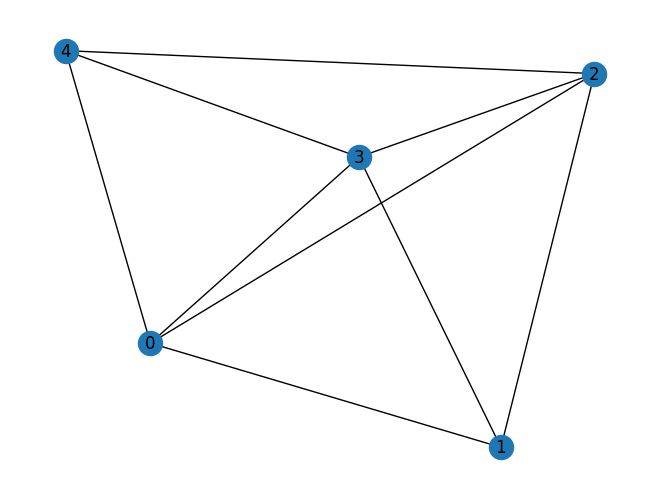

<Figure size 400x200 with 0 Axes>

In [9]:
# 第二种方法：使用add_weighted_edges_from()函数

# np.nonzero()获取非零元素位置索引
i,j = np.nonzero(A)
# 提出A中的非零元素
w = A[i,j]
# (i,j)就是无向图的边，wi的值为边对应的权值
edges=list(zip(i,j,w))
g = nx.Graph(A)
g.add_weighted_edges_from(edges)
nx.draw(g,with_labels=True)
plt.figure(figsize=(4, 2)) 

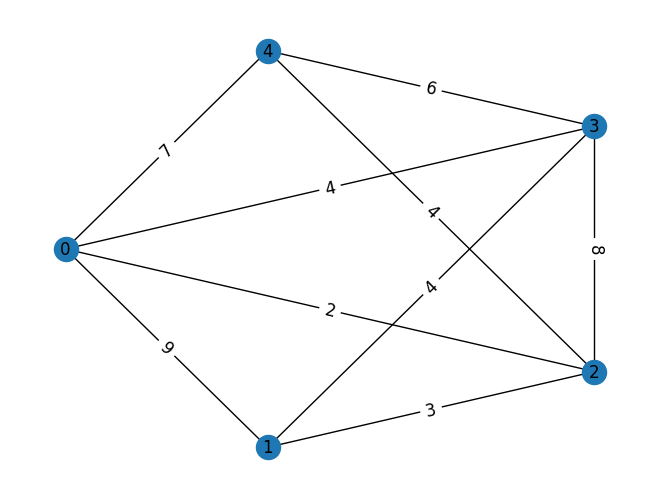

In [10]:
# 对得到无向图的边标注权重
# 节点在同心圆上分布
pos=nx.shell_layout(G)
nx.draw(G,pos,with_labels=True)
# 从G中获取边的权值
w = nx.get_edge_attributes(G,'weight')
# 绘图
nx.draw_networkx_edge_labels(G,pos,font_size=12,edge_labels=w)
plt.show()

#### 4.2.2 有向图

根据以下邻接矩阵创建有向图

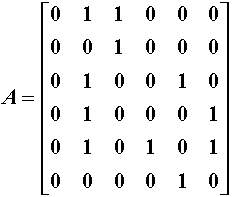

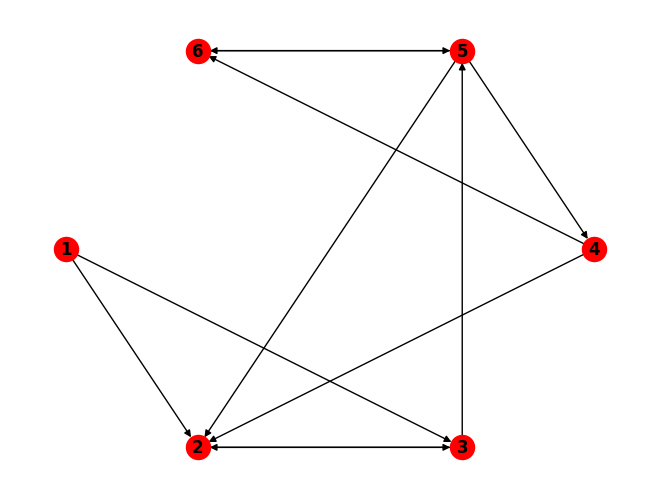

<Figure size 600x300 with 0 Axes>

In [11]:
#  创建有向图
G=nx.DiGraph()

List=[(1,2),(1,3),(2,3),(3,2),(3,5),(4,2),(4,6),
      (5,2),(5,4),(5,6),(6,5)]
# 添加顶点和弧
G.add_nodes_from(range(1,7))
G.add_edges_from(List)
# 节点在同心圆上分布
pos=nx.shell_layout(G) 
# font_weight：字体粗细；node_color：顶点颜色
nx.draw(G,pos,with_labels=True, font_weight='bold',node_color='r')
plt.figure(figsize=(6, 3)) 
plt.show()

### 4.3 图的矩阵表示与基本运算

> 来源：教材参考实现《数学建模算法与应用》第 04 章的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

In [ ]:
import networkx as nx
import numpy as np
import pprint

xs = [0, 5, 16, 20, 33, 23, 35, 25, 10]
ys = [15, 20, 24, 20, 25, 11, 7, 0, 3]
mgraph = [[np.abs(xs[i]-xs[j])+np.abs(ys[i]-ys[j]) for j in range(len(ys))] for i in range(len(xs))]
# pprint.pprint(mgraph)
elist = []
for i in range(len(xs)):
    for j in range(i):
        elist.append((str(i), str(j), mgraph[i][j]))

#pprint.pprint(elist)
G = nx.Graph()
G.add_weighted_edges_from(elist)
min_spantree = nx.algorithms.tree.mst.minimum_spanning_tree(G, weight='weight', algorithm='kruskal')
#nx.draw(G, pos=nx.spring_layout(G))  # use spring layout
nx.draw(min_spantree, pos=nx.spring_layout(min_spantree))  # use spring layout
#print(min_spantree.edges())
edge_weight = []
for edge in min_spantree.edges():
    edge_weight.append(mgraph[int(edge[0])][int(edge[1])])
#print(edge_weight)
#print(np.sum(edge_weight))

## 5. 小结

本次实验介绍了networkx库的基础操作、图的邻接矩阵和通过networkx库创建无向图及有向图。

通过本次实验需要掌握以下内容：
- 掌握networkx的基础操作
- 掌握使用networkx创建无向图和有向图